In [3]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols
import statsmodels.stats.multicomp as mc
import matplotlib.pyplot as plt
import pingouin as pg
import seaborn as sns

# Cargar la base de datos

In [4]:
data = pd.read_csv('students.csv')

# Filtrar los estudiantes graduados

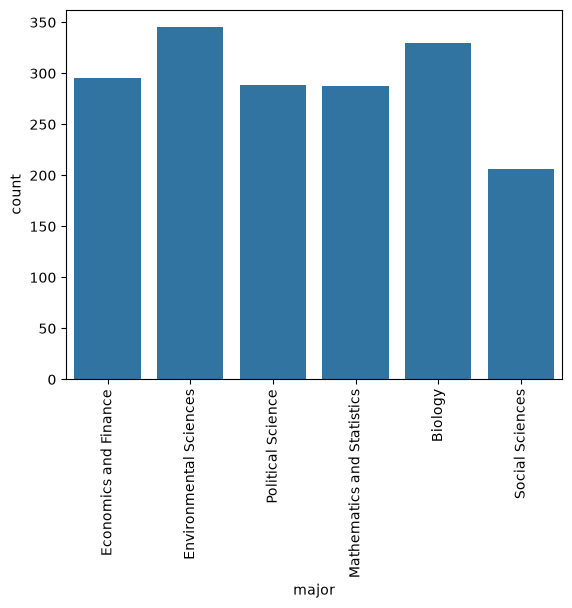

In [5]:
graduated_student = data[data['graduated'] == 1]
sns.countplot(data = graduated_student, x='major')
plt.xticks(rotation = 90)
plt.show()

specialties = ['Political Science', 'Economics and Finance', 'Environmental Sciences', 'Mathematics and Statistics', 'Biology', 'Social Sciences']
sample_size = 200

sample_list = []  

for specialty in specialties:
    sample = graduated_student[graduated_student['major'] == specialty].sample(sample_size, random_state = 42)
    sample_list.append(sample)

# Concatenar todas las muestras en un único DataFrame

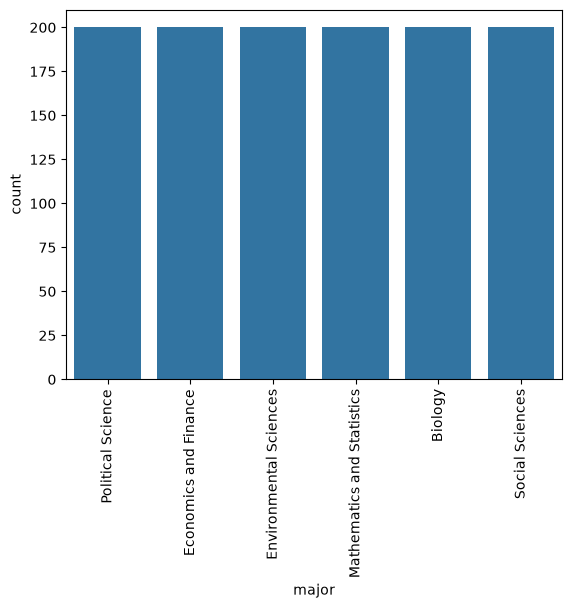

In [6]:
sample = pd.concat(sample_list)


sns.countplot(data = sample, x = 'major')
plt.xticks(rotation = 90)
plt.show()

# Resumen Estadístico

In [7]:
resumen = rp.summary_cont(sample['salary'].groupby(sample['major']))

NameError: name 'rp' is not defined

In [ ]:
# BoxPlot
sns.set(style="whitegrid")
sns.boxplot(x='major', y='salary', data=sample)
plt.xticks(rotation=90)
plt.show()

# BarPlot
sns.countplot(data=sample, x='major', hue='gender')
plt.xticks(rotation=90)
plt.title('Estudiantes por carrera y género')
plt.show()


In [ ]:
# Cumplimiento de supuestos
#Normalidad prueba de Shapiro-Wilk
#Ho:Normalidad(p>0.05)
#H1: No normalidad (p<0.05)
normality_test = pg.normality(sample, dv = 'salary', group = 'major')
print("Prueba de Normalidad (Shapiro-Wilk):\n", normality_test)
#Homocedasticidad prueba de Levene (sin normalidad)
#Ho:Homocedasticidad (p>0.05)
#H1: No Homocedasticidad (p<0.05)
pg.homoscedasticity(sample, dv='salary', 
                    group='major',method='levene')
#Homocedasticidad prueba de Bartlett (con normalidad)
#Ho:Homocedasticidad (p>0.05)
#H1: No Homocedasticidad (p<0.05)
pg.homoscedasticity(sample, dv='salary', 
                    group='major',method='bartlett')